# Per-dataset evaluation of the unified model

Loads the unified CRNN checkpoint and measures its accuracy on a random sample from each of the ten R `captcha` datasets, printing both captcha-level (exact match) and character-level accuracy and showing a labeled grid per dataset.

In [8]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from txtcaptcha import (
    Captcha,
    available_datasets,
    decrypt,
    load_model,
    read_captcha,
    sequence_accuracy,
)
from txtcaptcha.dataset import _label_from_path, _list_files

MODEL_PATH = Path('txtcaptcha_unified.pt')
DATA_ROOT = Path('data')
SAMPLE_SIZE = 200
SEED = 0

random.seed(SEED)

In [9]:
model = load_model(MODEL_PATH)
model.eval()
print(f'Loaded model with vocab size {len(model.vocab)}')

Loaded model with vocab size 62


In [10]:
def sample_dataset(name: str, n: int, seed: int = 0) -> Captcha:
    """Pick `n` random labeled files from the dataset directory and load them."""
    root = DATA_ROOT / name
    files = [p for p in _list_files(root) if _label_from_path(p) is not None]
    if not files:
        raise FileNotFoundError(f'No labeled files in {root}')
    rng = random.Random(seed)
    picked = rng.sample(files, min(n, len(files)))
    return read_captcha(picked, lab_in_path=True)

def char_accuracy(preds, golds) -> float:
    """Position-wise character accuracy, normalized by total gold characters.
    Length mismatches count every position up to max(len_p, len_g) as wrong."""
    total = 0
    correct = 0
    for p, g in zip(preds, golds):
        m = max(len(p), len(g))
        total += m
        correct += sum(1 for i in range(m) if i < len(p) and i < len(g) and p[i] == g[i])
    return correct / max(1, total)

In [11]:
def evaluate_dataset(name: str):
    cap = sample_dataset(name, SAMPLE_SIZE, seed=SEED)
    golds = [lab.lower() for lab in cap.labels]
    preds = decrypt(cap, model, case_sensitive=False)
    return {
        'dataset': name,
        'n': len(cap),
        'captcha_acc': sequence_accuracy(preds, golds),
        'char_acc': char_accuracy(preds, golds),
        'captcha': cap,
        'preds': preds,
        'golds': golds,
    }

results = {name: evaluate_dataset(name) for name in available_datasets()}

In [12]:
summary = pd.DataFrame([
    {k: r[k] for k in ('dataset', 'n', 'captcha_acc', 'char_acc')}
    for r in results.values()
]).sort_values('captcha_acc', ascending=False).reset_index(drop=True)
summary

,dataset,n,captcha_acc,char_acc
0,cadesp,200,1.000,1.000000
1,tjrs,200,1.000,1.000000
2,trt,200,0.995,0.999167
3,jucesp,200,0.985,0.997000
4,rfb,200,0.980,0.996667
5,esaj,200,0.975,0.990010
6,tjmg,200,0.970,0.994000
7,trf5,200,0.955,0.987500
8,sei,200,0.935,0.970000
9,tjpe,200,0.000,0.025000


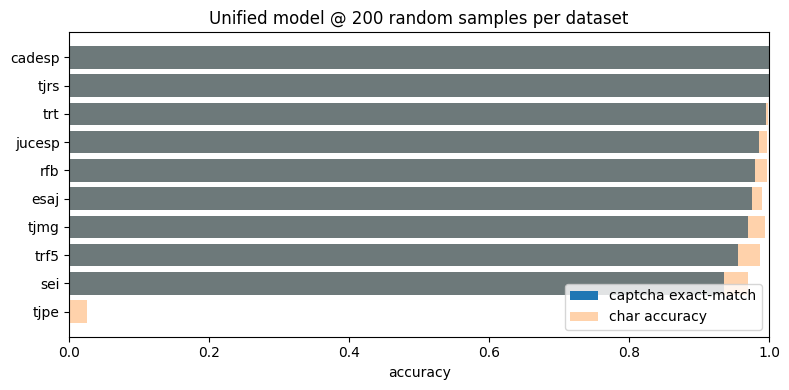

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(summary['dataset'], summary['captcha_acc'], label='captcha exact-match')
ax.barh(summary['dataset'], summary['char_acc'], alpha=0.35, label='char accuracy')
ax.set_xlim(0, 1)
ax.set_xlabel('accuracy')
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.set_title(f'Unified model @ {SAMPLE_SIZE} random samples per dataset')
fig.tight_layout()

## Labeled sample grids

For each dataset we show up to 12 random images. Green titles mean the prediction matched the gold label (case-insensitive); red titles highlight mistakes with `pred / gold`.

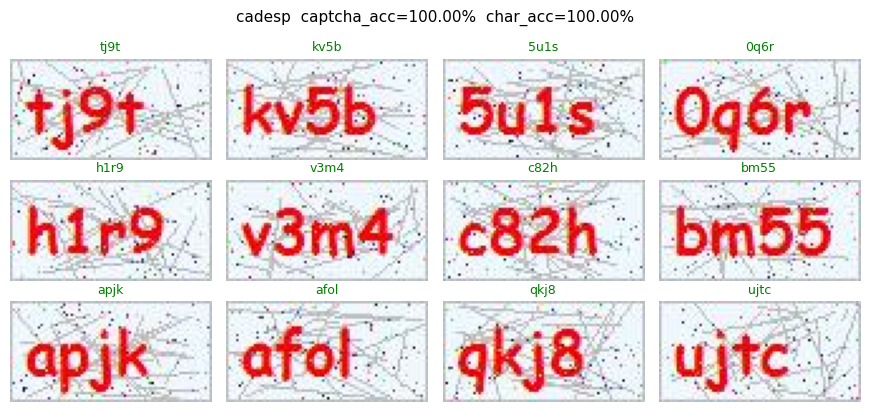

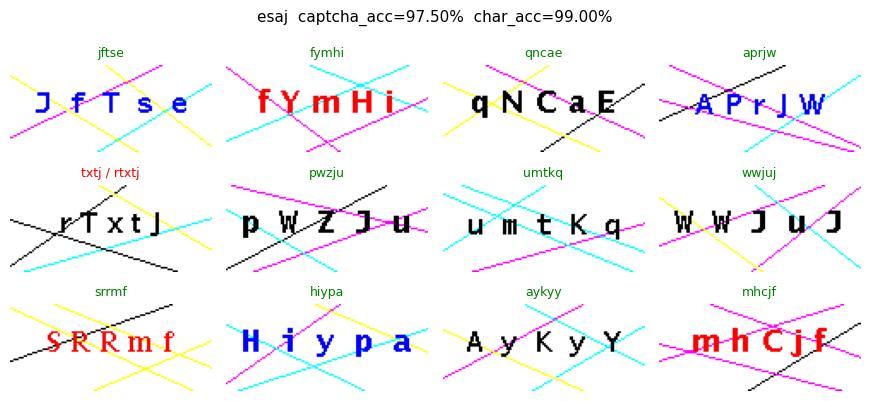

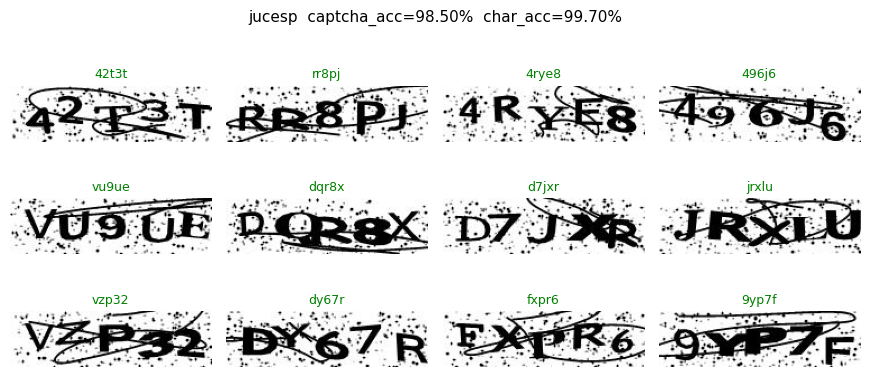

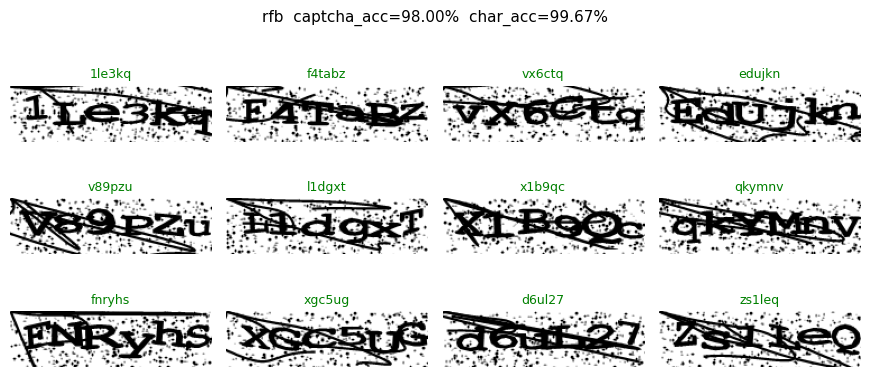

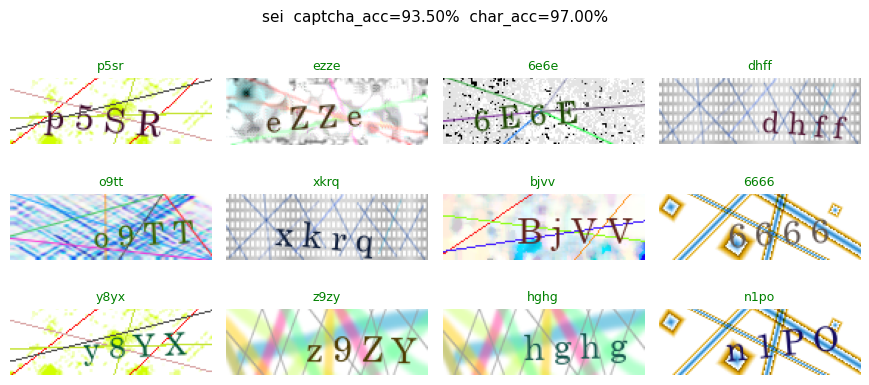

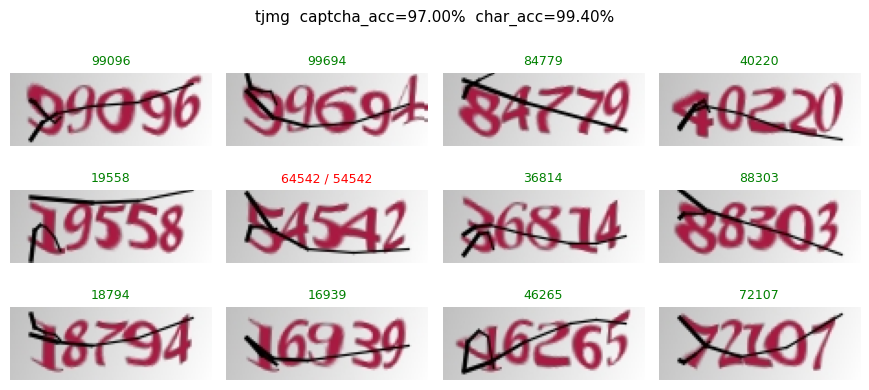

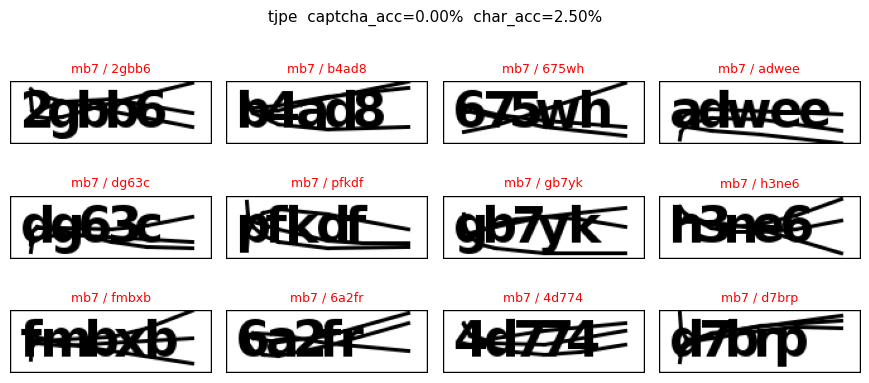

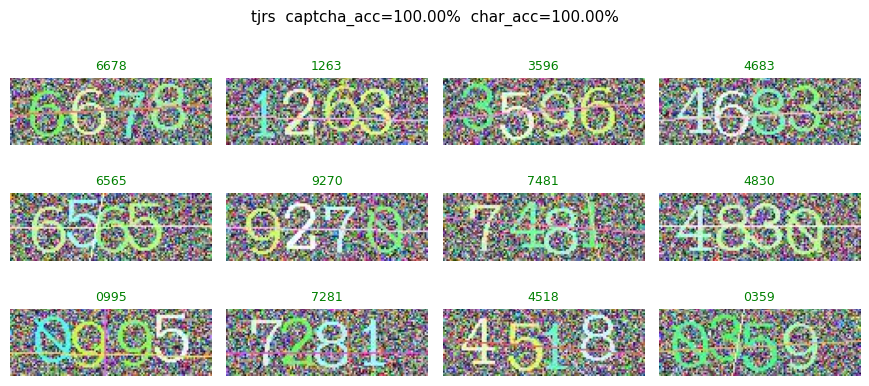

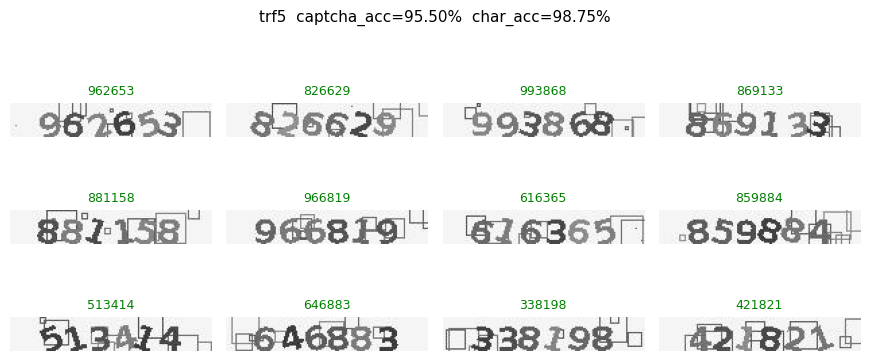

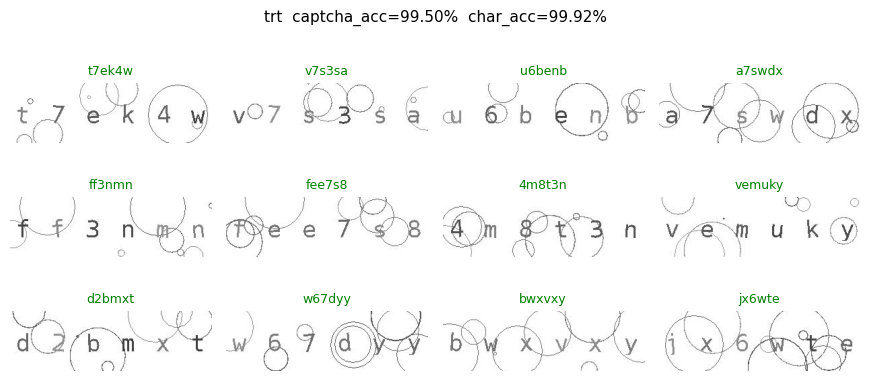

In [14]:
def show_predictions(result, n_show: int = 12, cols: int = 4):
    cap = result['captcha']
    preds = result['preds']
    golds = result['golds']
    rng = random.Random(SEED)
    idxs = rng.sample(range(len(cap)), min(n_show, len(cap)))
    rows = (len(idxs) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 1.4))
    axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]
    for ax, idx in zip(axes, idxs):
        ax.imshow(cap.images[idx])
        ax.axis('off')
        p, g = preds[idx], golds[idx]
        ok = p == g
        title = p if ok else f'{p} / {g}'
        ax.set_title(title, fontsize=9, color='green' if ok else 'red')
    for ax in axes[len(idxs):]:
        ax.axis('off')
    fig.suptitle(
        f"{result['dataset']}  "
        f"captcha_acc={result['captcha_acc']:.2%}  "
        f"char_acc={result['char_acc']:.2%}",
        fontsize=11,
    )
    fig.tight_layout()
    return fig

for name in available_datasets():
    show_predictions(results[name])
plt.show()